<figure>
  <IMG src="figures/logo-esi-sba.png" WIDTH=300 height="100" ALIGN="right">
</figure>

# Practical Trainining Series on Software Engineering For Data Science  
*By Dr. Belkacem KHALDI (b.khaldi@esi-sba.dz)*

# Notebook 4: Data Processing & Cleaning for Data Science: Data Ingestion and Wrangling with Pandas

The purpose of this [Jupyter Notebook] is to getting you introduced to the Data Processing & Cleaning for Data
Science: Data Ingestion and Wrangling with Pandas. It provides a set of practical Training challenges that allow grasping the different concepts presented in the lecture 5.

## Challenge 1
1. Connect to the `chinook.db` sqlite3 database available in the folder data.
2. Find the genre names with the longest average song length.

`Hint:`
join the tables with the genre name and song length and use the SQLite aggregate
function for the average along with a GROUP BY clause.


In [10]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('data/chinook.db')

query = """
SELECT 
    genres.Name AS Genre, 
    AVG(tracks.Milliseconds) / 1000.0 / 60.0 AS Average_Duration_Minutes
FROM genres
JOIN tracks ON genres.GenreId = tracks.GenreId
GROUP BY genres.GenreId
ORDER BY Average_Duration_Minutes DESC;
"""

df = pd.read_sql_query(query, conn)

conn.close()

df.head()

,Genre,Average_Duration_Minutes
0,Sci Fi & Fantasy,48.529717
1,Science Fiction,43.759151
2,Drama,42.921396
3,TV Shows,35.750684
4,Comedy,26.421062


## Challenge 2: Ingesting, Wrangling and Analyzing  iTune data

You've started a new data science position at the iTune department at Apple Company. 
The department wants to build, test, and evaluate new machine learning recommendation song models using a different source of data: in Excel file, in a csv file, and in the chinook.db SQLite database. They want you proceed with the data ingsestion and data wrangling procedures to provide a clean dataset to be used later for their machine learning based recommendation songs models.  

1. They particlarly asked you to load, clean, and analyze, and then deliver your results to the executive team and president.
You should deliver a small summary of your EDA work from pandas and save your cleaned and prepared data as a new Excel file. The data files are `chinook_data.xlsx`, `chinook_data.csv`, and `chinook.db` on the data folder existed within this notebook.

`Hint:`
1. Follow the procedures in the Lecture  - Slides: 13-17 - For data ingestion (Data loading from different sources).

2. Follow and test the procedures in the Lecture - Slides:18-22 - For Basic Exploratory Data Analysis (EDA).

3. Follow and test the procedures in the Lecture - Slides:23-27 - For Basic Data Cleaning Operations.

4. To save your cleaned dataset in an excel file use the pandas built-in method: `pandas.DataFrame.to_excel`.


                                    Track                           Composer  \
0  All the Best Cowboys Have Daddy Issues                                NaN   
1                               Beira Mar                       Gilberto Gil   
2                                  Brasil  Milton Nascimento, Fernando Brant   
3                            Ben Franklin                                NaN   
4            O Último Romântico (Ao Vivo)                                NaN   

   Milliseconds        Bytes  UnitPrice     Genre  \
0     2555492.0  211743651.0       1.99  TV Shows   
1      295444.0    9597994.0       0.99     Latin   
2      155428.0    5252560.0       0.99     Latin   
3     1271938.0  264168080.0       1.99    Comedy   
4      231993.0    7692697.0       0.99     Latin   

                                             Album             Artist  
0                                   Lost, Season 1               Lost  
1                                        Unplugged      

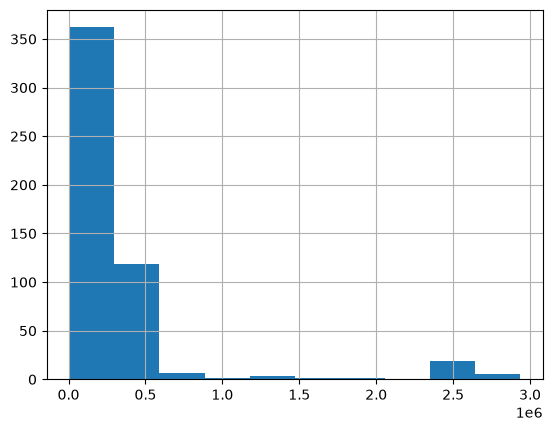

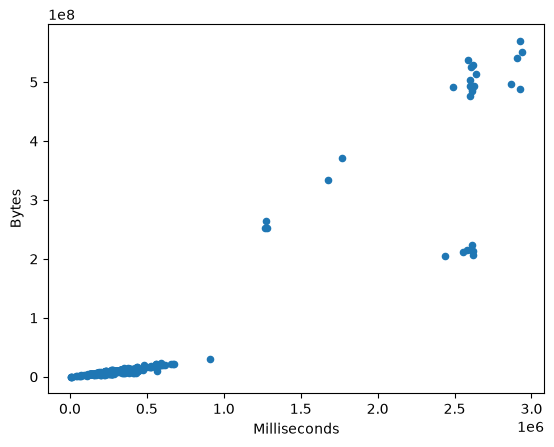

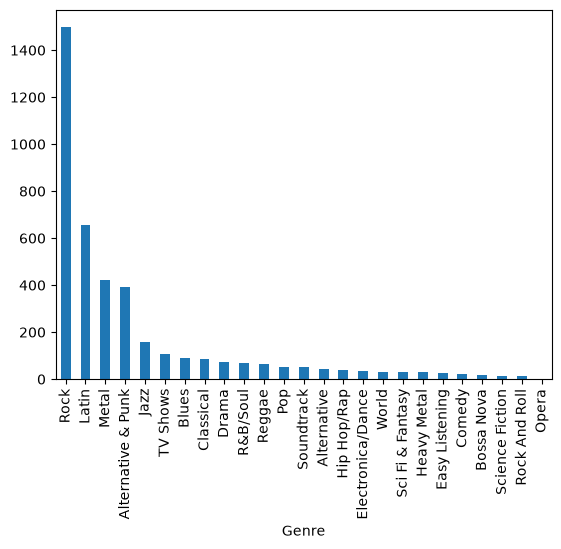

Duplicates: 18
After: 0
(0, 8)


In [16]:
#Your Solution here

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# 1. Ingestion
csv_df = pd.read_csv('data/chinook_data.csv', sep=',', decimal='.')
excel_df = pd.read_excel('data/chinook_data.xlsx')

conn = sqlite3.connect('data/chinook.db')
sql_df = pd.read_sql_query("""
SELECT t.name AS Track, t.composer AS Composer, t.unitprice AS UnitPrice,
       g.name AS Genre, a.title AS Album, r.name AS Artist
FROM tracks t
JOIN genres g ON t.genreid = g.genreid
JOIN albums a ON t.albumid = a.albumid
JOIN artists r ON a.artistid = r.artistid;
""", conn)

itunes_df = pd.concat([csv_df, excel_df, sql_df], ignore_index=True)

# 2. EDA
print(itunes_df.head())
print(itunes_df.tail())
print("shape:")
print(itunes_df.shape)
itunes_df.info()
print(itunes_df.isna().sum())
print(itunes_df.describe())
print(itunes_df['Genre'].mode()[0])
print(itunes_df['Genre'].value_counts())
print(itunes_df.corr(numeric_only=True))

itunes_df['Milliseconds'].hist(); plt.show()
itunes_df.plot.scatter(x='Milliseconds', y='Bytes'); plt.show()
itunes_df['Genre'].value_counts().plot.bar(); plt.show()

# 3. Cleaning
# a) irrelevant data
itunes_df = itunes_df.drop(columns='Composer')
non_music = ['Drama', 'TV Shows', 'Sci Fi & Fantasy', 'Science Fiction', 'Comedy']
itunes_df = itunes_df[~itunes_df['Genre'].isin(non_music)]

# b) duplicates
print("Duplicates:", itunes_df.duplicated().sum())
itunes_df = itunes_df.drop_duplicates()
print("After:", itunes_df.duplicated().sum())

# c) missing values (Milliseconds/Bytes are NaN for csv+sql rows)
itunes_df['UnitPrice'] = itunes_df['UnitPrice'].fillna(itunes_df['UnitPrice'].mode()[0])
itunes_df['Milliseconds'] = itunes_df['Milliseconds'].fillna(itunes_df['Milliseconds'].median())
itunes_df['Bytes'] = itunes_df['Bytes'].fillna(itunes_df['Bytes'].median())

# d) outliers (IQR)
def remove_outliers(df, column):
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    return df.loc[(df[column] > q1 - 1.5 * iqr) & (df[column] < q3 + 1.5 * iqr)]

itunes_df = remove_outliers(itunes_df, 'Milliseconds')

# e) datatypes + standardization
itunes_df['Milliseconds'] = itunes_df['Milliseconds'].astype(int)
itunes_df['Bytes'] = itunes_df['Bytes'].astype(int)
itunes_df['Seconds'] = itunes_df['Milliseconds'] / 1000
for c in ['Track', 'Genre', 'Album', 'Artist']:
    itunes_df[c] = itunes_df[c].str.strip()

# 4. Export
itunes_df.to_excel('data/itunes_clean.xlsx', index=False)
print(itunes_df.shape)

## Challenge 03: Data Cleaning Challenge for Oil & Gas Dataset

#### Context:
You have recently joined as a data scientist specialist in the Data Science Department of the prominent energy company, Sonatrach. Specifically, you are assigned to the Gas and Oil complex located in Hassi Messoud, Ouargla. The department has initiated a project focused on developing, testing, and assessing various time series forecasting machine learning models for the analysis of daily Gaz & Oil production. 

Your immediate task involves the thorough cleaning and provision of a fundamental exploratory data analysis (EDA) for the dataset stored in the `data/oil_gas_data.csv` file. This dataset has various data quality issues that need to be addressed to ensure its accuracy and reliability. The team you collaborate with is relying on your expertise to ensure the dataset's integrity and to gain insightful initial observations through exploratory analysis.


#### Dataset Description:
The dataset (`oil_gas_data.csv`) includes the following columns:

* `well_id`: Unique identifier for each well. However, there is only one identifier in the provided dataset.
* `date`: Date of observation.
* `drilling_depth`: Depth of drilling in feet.
* `drilling_speed`: Drilling speed in feet per hour.
* `well_temperature`: Temperature of the well in Celsius.
* `drilling_success`: Binary valid indicator (0 or 1) representing the unseccess or success of the drilling operation. However, there might be out-of-range values (not 0 or 1) present.
* `daily_oil_production`: Daily oil production in barrels.
* `daily_gas_production`: Daily gas production in cubic feet.

#### Tasks:

1. Proceed with General Data Cleaning steps to provide a clean dataset.
4. Save your cleaned dataset into a csv file named `cleaned_oil_gas_data.csv`


In [27]:
#Your Solution here

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# --- Ingestion (file is ';'-separated and Latin-1 encoded) ---
df = pd.read_csv('data/oil_gas_data.csv', sep=';', encoding='latin-1')

# --- Basic EDA ---
print(df.head(), df.tail(), sep="\n\n")
print(df.shape)
df.info()
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique well_id:", df['well_id'].nunique())
print(df['drilling_success'].value_counts())

# --- Remove irrelevant data ---
df = df.drop(columns=['well_id'])

# --- Fix datatypes: strip units, parse dates ---
num_cols = ['drilling_depth', 'drilling_speed', 'well_temperature',
            'daily_oil_production', 'daily_gas_production']
for c in num_cols:
    df[c] = df[c].str.extract(r'^\s*(-?\d+\.?\d*)')[0].astype(float)  # 'nan barrels/day' -> NaN

df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
df = df.sort_values('date').reset_index(drop=True)

# --- Duplicates ---
df = df.drop_duplicates().reset_index(drop=True)

# --- Out-of-range drilling_success (only 0/1 valid): NaN -> mode ---
invalid = ~df['drilling_success'].isin([0, 1])
df.loc[invalid, 'drilling_success'] = np.nan
df['drilling_success'] = df['drilling_success'].fillna(df['drilling_success'].mode()[0]).astype(int)

# --- Outliers (IQR): set to NaN instead of dropping rows, to keep the daily series continuous ---
for c in num_cols:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    mask = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)
    print(f"{c}: {mask.sum()} outliers")
    df.loc[mask, c] = np.nan

# --- Missing values: KNN imputation (oil/gas are strongly correlated with depth) ---
feat = ['drilling_depth', 'daily_oil_production', 'daily_gas_production']
scaler = StandardScaler()
scaled = scaler.fit_transform(df[feat])
df[feat] = scaler.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(scaled))
df[num_cols] = df[num_cols].round(3)

# --- Validation ---
assert df.isna().sum().sum() == 0
assert df['drilling_success'].isin([0, 1]).all()
df.info()
print(df.describe())

# --- Save ---
df.to_csv('data/cleaned_oil_gas_data.csv', index=False)

         date                               well_id drilling_depth  \
0  01/01/2022  cda1607e-ad63-4932-a207-01ba25d6f20c   8352.41 feet   
1  02/01/2022  cda1607e-ad63-4932-a207-01ba25d6f20c   5774.25 feet   
2  03/01/2022  cda1607e-ad63-4932-a207-01ba25d6f20c   4815.45 feet   
3  04/01/2022  cda1607e-ad63-4932-a207-01ba25d6f20c   4946.49 feet   
4  05/01/2022  cda1607e-ad63-4932-a207-01ba25d6f20c   4723.77 feet   

    drilling_speed well_temperature  drilling_success  daily_oil_production  \
0  42.04 feet/hour        135.24 °C                 1  5249.935 barrels/day   
1  42.96 feet/hour         97.66 °C                 0    3695.4 barrels/day   
2  51.21 feet/hour         99.11 °C                 1  3259.092 barrels/day   
3  79.24 feet/hour         60.27 °C                 1  3345.738 barrels/day   
4  62.42 feet/hour        257.44 °C                 1   3214.31 barrels/day   

      daily_gas_production  
0  5468.664 cubic feet/day  
1   3953.42 cubic feet/day  
2  3529.442 cubic

## Challenge 4: Ingesting, Wrangling and Analyzing Bitcoin price data


You have just joined a financial company as a new data scientist. The company is  interested in the Bitcon market and you are working with a team that aims to ingest data and then clean, and analyse the final dataset to be used later to build and evaluate machine learning models for Bitcon Price forecasting.

The company is working with two datasets coming from two different sources and is only interested in the `BTCUSD` currency: 
1. One dataset is json file locally existed in the data folder: `bitcoin_price.json`. This file contains data up to `2020-11-27`
2. The other uses a real time data flow that comes from yahoo finance api service. The company wants to collect real time data beginning from `2020-11-28` to `2022-10-31`.

You are asked to do the required checklist procedures and operations to load, clean, and analyse, and then deliver your results to the executive team with providing a short summaray of your prelimanary EDA work from pandas and save the cleaner dataset as a new csv file. 
Note that the 

`Hint:`

1. To load a json file into a dataframe use the snipet code below:

```python
import json

with open('<path_to_your_json_file>') as f:
    data = json.load(f)

btc_df_jsn=pd.DataFrame.from_dict(data)
```

This code uses the `json` built-in python module to open a json file and load it in an object data. Then we use the `from_dict()` pandas method to transform the json data into a DataFrame.

2. To get real time data flow from the yahoo finance api sevice we will use the `yfinance` module. 
    * So, first install the module in your environment using  `conda install yfinance`.
    * Then use the code below to get real data. Test with the periode from `2020-01-01` to `2026-10-31`.

```python
import yfinance as yf

btc_yf_df = yf.download('BTC-USD', # The currency we are intersted in
                   start='<start_date>', # The starting date
                   end='<end_date>', # The starting date
                   interval='1d' # The frequency of collecting the data. here 1 day
                  )
```

3. Get a look of the two DataFrames and see what are the common columns and what differ one to another.
    * You will notice that the  json DataFrame is indexed numericaly wherease the yahoo DataFrame is indexed by Date. So, you have to uniform the index for both DataFrames. In this case we will change the json DataFrame  index by Date.
        1. To do that, first rename the column `time` to `Date` by using the built-in pandas method: `rename()` as follows:
        
        ```python
        rename(columns ={'<old_col_name>':'<new_col_name>'}, inplace = True)
         ```
         
        2. What is the datatype of the new Date column in the json DataFrame?
            * You will notice that it is a `datetime64[ns]` datatype, which means the number of seconds since 1-1-1970. To make it date fomat like the yahoo DataFrame, convert the column to a pandas datetime datatype by using the following code: 
         
          ```python
              btc_df['<column_name>'] = pd.to_datetime(btc_df['<column_name>'], unit='ms')
          ```
         
        3. To change the index of your dataframe use the `set_index` built-in pandas function:
        ```python
              set_index('<column_name>', inplace=True)
        ```
            * The remaining common columns labels in both DataFrames are not uniformed. The json DataFrame uses lowercase strings,  while the yahoo DataFrame uses a first letter world uppercase string.
                  1. Change the column labels of the yahoo DataFrame to lowercase strings. Adjust the following code accordingly:
             ```python
                data_frame.columns= data_frame.columns.str.lower()
             ```
             
4. Concatenate the two dataframe into one dataset.
5. Do The basic EDA cheklist procedures on the resulting dataset:
   * Do few time series plots: 
       * open, close, high, low, volume with regards to Date
   * Print the correlation matrix.
6. Do the General Data Cleaning Checklist operations to see if ther is still cleaning operations to accomplish.
    * Most particularly, you will notice a NaN values in both `adj close` and `symbole` columns. What is your suggestion to deal with this missing values given that the company is not interest at all on the `adj close` data. 	
7. Save your cleaner dataframe into a csv file.
    * Use the `pandas.DataFrame.to_csv` method.
             

   symbol           time        open       close       high        low  \
0  btcusd  1364688000000   92.500000   93.033000   93.74999   91.00000   
1  btcusd  1364774400000   93.250000  103.999000  105.90000   92.49999   
2  btcusd  1364860800000  104.000000  118.229354  118.38670   99.00000   
3  btcusd  1364947200000  117.958261  134.700000  146.88000  101.51088   
4  btcusd  1365033600000  134.716560  132.899000  143.00000  119.00000   

         volume  
0   3083.079791  
1   5224.401313  
2   8376.527478  
3  12996.245072  
4   6981.668305  
symbol        str
time        int64
open      float64
close     float64
high      float64
low       float64
volume    float64
dtype: object
Price          Adj Close         Close          High           Low  \
Ticker           BTC-USD       BTC-USD       BTC-USD       BTC-USD   
Date                                                                 
2020-11-28  17717.414062  17717.414062  17853.939453  16910.652344   
2020-11-29  18177.484375  1

,symbol,open,close,high,low,volume,adj close
Date,,,,,,,
2013-03-31,btcusd,92.500000,93.033000,93.74999,91.00000,3083.079791,NaN
2013-04-01,btcusd,93.250000,103.999000,105.90000,92.49999,5224.401313,NaN
2013-04-02,btcusd,104.000000,118.229354,118.38670,99.00000,8376.527478,NaN
2013-04-03,btcusd,117.958261,134.700000,146.88000,101.51088,12996.245072,NaN
2013-04-04,btcusd,134.716560,132.899000,143.00000,119.00000,6981.668305,NaN


,symbol,open,close,high,low,volume,adj close
Date,,,,,,,
2022-10-27,NaN,20772.802734,20285.835938,20854.044922,20255.373047,4.962511e+10,20285.835938
2022-10-28,NaN,20287.957031,20595.351562,20724.980469,20086.068359,4.399472e+10,20595.351562
2022-10-29,NaN,20595.103516,20818.476562,20988.394531,20566.484375,4.036984e+10,20818.476562
2022-10-30,NaN,20817.982422,20635.603516,20917.005859,20547.462891,3.148635e+10,20635.603516
2022-10-31,NaN,20633.695312,20495.773438,20795.320312,20287.458984,4.566847e+10,20495.773438


<class 'pandas.DataFrame'>
DatetimeIndex: 3496 entries, 2013-03-31 to 2022-10-31
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   symbol     2793 non-null   str    
 1   open       3496 non-null   float64
 2   close      3496 non-null   float64
 3   high       3496 non-null   float64
 4   low        3496 non-null   float64
 5   volume     3496 non-null   float64
 6   adj close  703 non-null    float64
dtypes: float64(6), str(1)
memory usage: 218.5 KB
symbol        703
open            0
close           0
high            0
low             0
volume          0
adj close    2793
dtype: int64
               open         close          high           low        volume  \
count   3496.000000   3496.000000   3496.000000   3496.000000  3.496000e+03   
mean   10896.595610  10901.309764  11188.385089  10566.711566  7.930372e+09   
std    15690.355517  15686.847709  16090.192802  15229.366139  1.837526e+10   
min       66.120000   

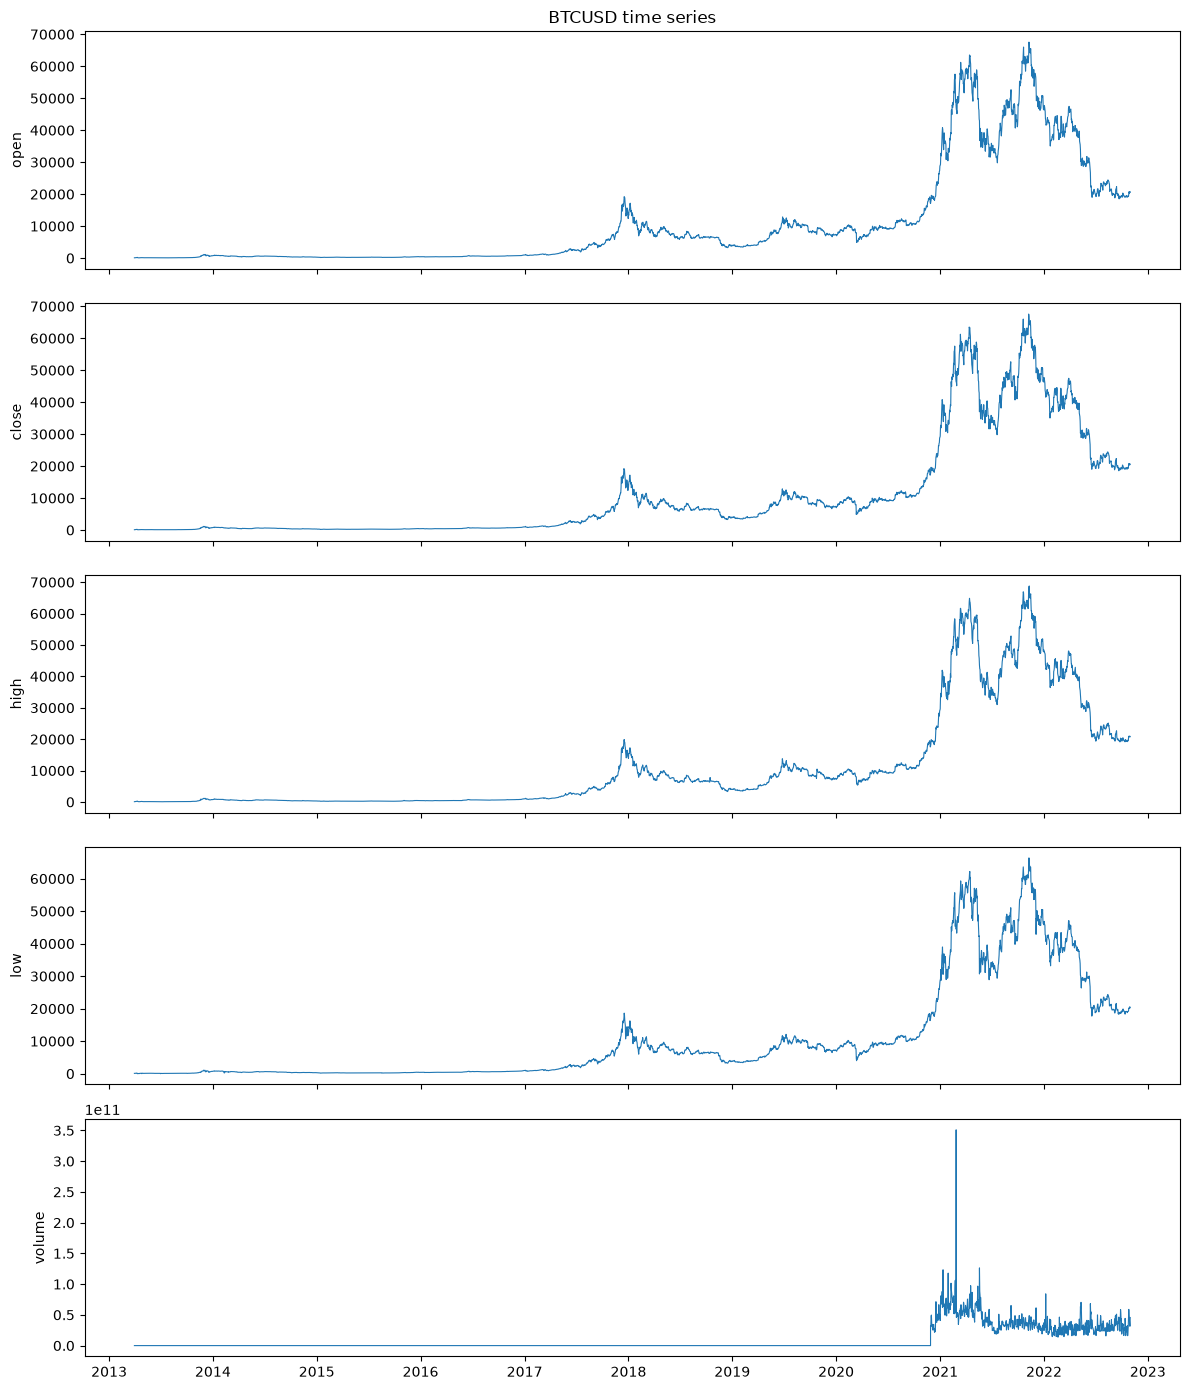

               open     close      high       low    volume  adj close
open       1.000000  0.998892  0.999553  0.999163  0.813414   0.993036
close      0.998892  1.000000  0.999504  0.999422  0.811959   1.000000
high       0.999553  0.999504  1.000000  0.999081  0.816682   0.996910
low        0.999163  0.999422  0.999081  1.000000  0.805970   0.996417
volume     0.813414  0.811959  0.816682  0.805970  1.000000   0.226482
adj close  0.993036  1.000000  0.996910  0.996417  0.226482   1.000000
Invalid low values: 8
Missing days: 7
Duplicated rows: 0
<class 'pandas.DataFrame'>
DatetimeIndex: 3502 entries, 2013-03-31 to 2022-10-31
Freq: D
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   open    3502 non-null   float64
 1   close   3502 non-null   float64
 2   high    3502 non-null   float64
 3   low     3502 non-null   float64
 4   volume  3502 non-null   float64
dtypes: float64(5)
memory usage: 164.2 KB


In [29]:
#Your Solution here

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# 1. Data ingestion
with open('data/bitcoin_price.json') as f:
    data = json.load(f)
btc_df_jsn = pd.DataFrame.from_dict(data)

btc_yf_df = yf.download('BTC-USD', start='2020-11-28', end='2022-11-01',
                        interval='1d', auto_adjust=False, progress=False)

# 2. Data inspection
print(btc_df_jsn.head(), btc_df_jsn.dtypes, sep="\n")
print(btc_yf_df.head(), btc_yf_df.dtypes, sep="\n")

# 3. Uniformize the dataframes
btc_df_jsn.rename(columns={'time': 'Date'}, inplace=True)
btc_df_jsn['Date'] = pd.to_datetime(btc_df_jsn['Date'], unit='ms')
btc_df_jsn.set_index('Date', inplace=True)

if isinstance(btc_yf_df.columns, pd.MultiIndex):
    btc_yf_df.columns = btc_yf_df.columns.get_level_values(0)
btc_yf_df.columns.name = None
btc_yf_df.columns = btc_yf_df.columns.str.lower()

# 4. Concatenation
btc_df = pd.concat([btc_df_jsn, btc_yf_df])
print(btc_df.shape)
print(btc_df.index.duplicated().sum(), "duplicated dates")

# 5. Basic EDA
display(btc_df.head())
display(btc_df.tail())
btc_df.info()
print(btc_df.isna().sum())
print(btc_df.describe())

fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True)
for ax, col in zip(axes, ['open', 'close', 'high', 'low', 'volume']):
    ax.plot(btc_df.index, btc_df[col], lw=0.8)
    ax.set_ylabel(col)
axes[0].set_title('BTCUSD time series')
plt.tight_layout()
plt.show()

print(btc_df.drop(columns=['symbol']).corr())

# 6. Data cleaning
# duplicated dates
btc_df = btc_df[~btc_df.index.duplicated(keep='last')].sort_index()

# irrelevant columns
btc_df = btc_df.drop(columns=['adj close', 'symbol'])

# invalid low values
price_floor = btc_df[['open', 'close']].min(axis=1)
bad_low = btc_df['low'] < 0.5 * price_floor
print("Invalid low values:", bad_low.sum())
btc_df.loc[bad_low, 'low'] = price_floor[bad_low]

# missing days
full_idx = pd.date_range(btc_df.index.min(), btc_df.index.max(), freq='D', name='Date')
print("Missing days:", len(full_idx) - len(btc_df))
btc_df = btc_df.reindex(full_idx)
btc_df = btc_df.interpolate(method='time')

# final checks
print("Duplicated rows:", btc_df.duplicated().sum())
assert btc_df.isna().sum().sum() == 0
btc_df.info()

# 7. Export
btc_df.to_csv('data/cleaned_bitcoin_price.csv')